# Dataset preparation



## 1. 📥​ Imports

In [13]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "tcibench" / "preparation" / "metadata.json").is_file()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the tcibench project.")

sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from tcibench.preparation import Dataset, load_dataset, load_metadata, plot_feature_distributions

In [15]:
RAW_ROOT = PROJECT_ROOT / "data" / "raw"

DATASET_PATHS = {
    "diabetes": RAW_ROOT / "diabetes.csv",
    "sick": RAW_ROOT / "sick.arff",
    "predictive_maintenance": RAW_ROOT / "predictive_maintenance.csv",
}

## 2. ⚙️​​ Utils

In [16]:
def inspect_dataset(dataset_id: str):
    """Show metadata, cleaning, split, class balance, and feature distributions."""
    if dataset_id not in DATASET_PATHS:
        raise ValueError(f"Choose one of: {', '.join(DATASET_PATHS)}")

    metadata = load_metadata(dataset_id)
    raw = load_dataset(DATASET_PATHS[dataset_id])
    dataset = Dataset(raw, metadata)
    cleaned, cleaning_stats = dataset.preprocessing.clean(raw)
    folds = dataset.preprocessing.split(cleaned)
    train, test, split_audit = folds[0]

    print(f"{metadata.display_name} | target: {metadata.target_column}")
    display(pd.DataFrame(metadata.columns).T)
    print(f"Raw data: {raw.shape[0]} rows, {raw.shape[1]} columns")
    display(raw.head())

    print("Cleaning")
    display(pd.Series(cleaning_stats, name="value").to_frame())
    display(cleaned.head())

    print("Train/test split")
    display(pd.Series(split_audit, name="value").to_frame())
    target = metadata.target_column
    display(pd.DataFrame({
        "train_count": train[target].value_counts(),
        "train_proportion": train[target].value_counts(normalize=True),
        "test_count": test[target].value_counts(),
        "test_proportion": test[target].value_counts(normalize=True),
    }).fillna(0).sort_index())

    figure = plot_feature_distributions(cleaned, train, test, metadata)
    plt.show()
    plt.close(figure)
    return train, test

## 3. 🔎 Inspect a dataset

AI4I 2020 Predictive Maintenance | target: Target


,type,description
Type,categorical,"Product quality variant: L (low), M (medium) o..."
Air temperature (K),numeric,Air temperature in kelvin.
Process temperature (K),numeric,Process temperature in kelvin.
Rotational speed (rpm),numeric,Rotational speed in revolutions per minute.
Torque (Nm),numeric,Torque in newton-metres.
Tool wear (min),numeric,Tool wear in minutes.
Target,categorical,Machine failure (0: no failure; 1: failure).


Raw data: 10000 rows, 10 columns


,UDI,Product ID,Type,Air temperature (K),Process temperature (K),Rotational speed (rpm),Torque (Nm),Tool wear (min),Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


Cleaning


,value
original_rows,10000
cleaned_rows,10000
dropped_columns,"[UDI, Product ID, Failure Type]"
all_missing_columns,[]
missing_values_before_cleaning,0
missing_values_by_column_before_cleaning,{}
removed_missing_rows,0
removed_duplicate_rows,0
numeric_decimals,4
target_counts_before_cleaning,"{'0': 9661, '1': 339}"


,Type,Air temperature (K),Process temperature (K),Rotational speed (rpm),Torque (Nm),Tool wear (min),Target
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


Train/test split


,value
fold,1
n_splits,5
split_seed,42
input_rows,10000
train_rows,8000
test_rows,2000
train_target_counts,"{'0': 7728, '1': 272}"
test_target_counts,"{'0': 1933, '1': 67}"
majority_class,0
minority_class,1


,train_count,train_proportion,test_count,test_proportion
Target,,,,
0,7728,0.966,1933,0.9665
1,272,0.034,67,0.0335


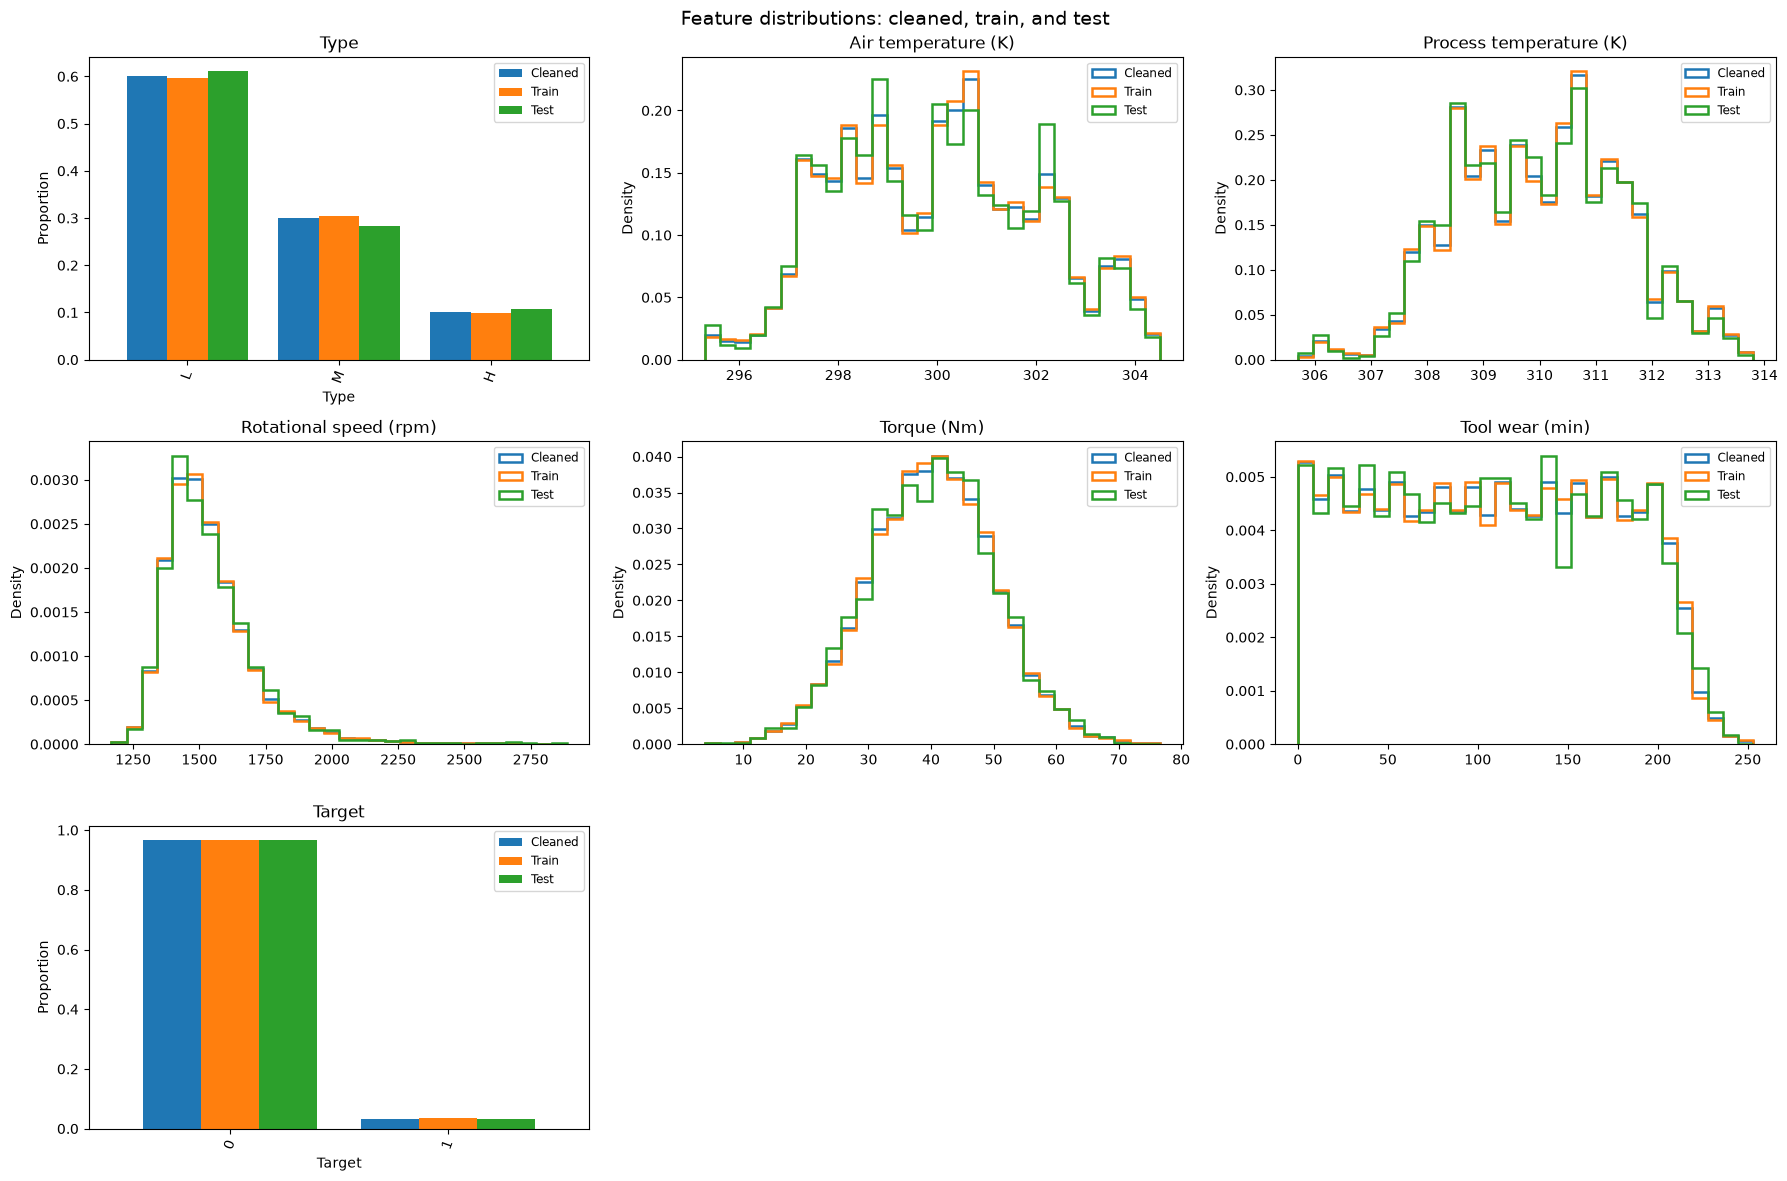

In [17]:
train, test = inspect_dataset("predictive_maintenance")